In [2]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


**Chargement des données** 

In [3]:

cac = yf.download(
    "^FCHI",
    start="2014-12-15",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

cac.head()


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2014-12-15,4005.379883,4005.379883,4144.310059,4000.800049,4094.459961,149438700
2014-12-16,4093.199951,4093.199951,4094.189941,3926.340088,4027.510010,248244700
2014-12-17,4111.910156,4111.910156,4131.810059,4035.300049,4052.229980,143182000
2014-12-18,4249.490234,4249.490234,4249.490234,4159.950195,4186.259766,214450700
2014-12-19,4241.649902,4241.649902,4291.200195,4202.069824,4282.390137,214972700


In [4]:

sp500 = yf.download(
    "^GSPC",
    start="2014-12-15",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

sp500.head()


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2014-12-15,1989.630005,1989.630005,2018.689941,1982.260010,2005.030029,4361990000
2014-12-16,1972.739990,1972.739990,2016.890015,1972.560059,1986.709961,4958680000
2014-12-17,2012.890015,2012.890015,2016.750000,1973.770020,1973.770020,4942370000
2014-12-18,2061.229980,2061.229980,2061.229980,2018.979980,2018.979980,4703380000
2014-12-19,2070.649902,2070.649902,2077.850098,2061.030029,2061.040039,6465530000


Calculer les rendements

In [5]:

prix_cac = cac["Close"].dropna()
prix_sp500 = sp500["Close"].dropna()


In [6]:

prix = pd.concat([prix_cac, prix_sp500], axis=1)

prix.columns = ["CAC40", "SP500"]

prix = prix.loc["2015-01-01":"2024-12-31"]

prix.head()


,CAC40,SP500
Date,,
2015-01-02,4252.290039,2058.199951
2015-01-05,4111.359863,2020.579956
2015-01-06,4083.500000,2002.609985
2015-01-07,4112.729980,2025.900024
2015-01-08,4260.189941,2062.139893


**Représentation des prix**

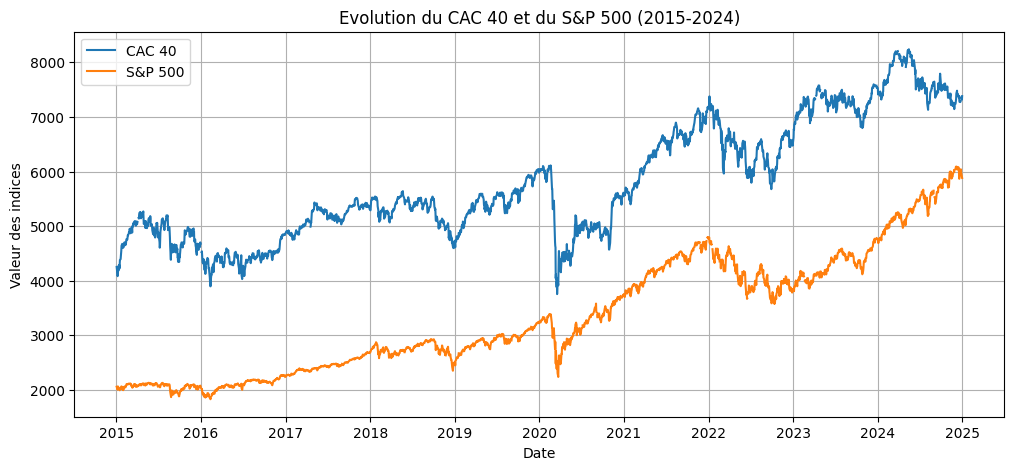

In [7]:

plt.figure(figsize=(12, 5))

plt.plot(prix.index, prix["CAC40"], label="CAC 40")
plt.plot(prix.index, prix["SP500"], label="S&P 500")

plt.title("Evolution du CAC 40 et du S&P 500 (2015-2024)")
plt.xlabel("Date")
plt.ylabel("Valeur des indices")
plt.legend()
plt.grid()
plt.show()

**Rendements logarithmiques** 

In [9]:

rendements_cac = np.log(prix_cac / prix_cac.shift(1))
rendements_sp500 = np.log(prix_sp500 / prix_sp500.shift(1))

rendements = pd.concat(
    [rendements_cac, rendements_sp500],
    axis=1
)

rendements.columns = ["CAC40", "SP500"]

rendements = rendements.loc["2015-01-01":"2024-12-31"]

rendements.head()


,CAC40,SP500
Date,,
2015-01-02,-0.004800,-0.000340
2015-01-05,-0.033704,-0.018447
2015-01-06,-0.006799,-0.008933
2015-01-07,0.007133,0.011563
2015-01-08,0.035227,0.017730
